# GitHub & Collaboration

Git becomes a team tool when repositories are connected. A **remote** is another copy of the repository, usually on a hosting service such as GitHub, GitLab or Codeberg. Developers **push** their commits to the remote and **pull** the commits of others.

**After this lesson you can:**

1. Add a remote and use `clone`, `push`, `fetch` and `pull`.
2. Keep files out of Git with `.gitignore`.
3. Explain the GitHub flow: branch → commit → push → pull request → review → merge.
4. Analyse who changed what with `git log` and `git blame`.

The lesson uses a **bare repository** in a local folder as the remote. A bare repository has no working directory; GitHub stores repositories the same way. The Git commands are exactly the ones you use with GitHub.

In [1]:
import os
import subprocess
import tempfile
from pathlib import Path

# Use a neutral identity and ignore your personal Git configuration, so the output is the same on every machine.
os.environ.update({"GIT_CONFIG_GLOBAL": os.devnull, "GIT_CONFIG_NOSYSTEM": "1",
                   "GIT_AUTHOR_NAME": "Ayse", "GIT_AUTHOR_EMAIL": "ayse@example.com",
                   "GIT_COMMITTER_NAME": "Ayse", "GIT_COMMITTER_EMAIL": "ayse@example.com"})
WORK = Path(tempfile.mkdtemp())

class Output(str):
    """The text output of a command; the notebook does not display it a second time."""
    def _ipython_display_(self):
        pass

def short(text: str) -> str:
    return text.replace(str(WORK), "<work>").replace(str(Path.cwd().parent), "<repo>")

def sh(cmd: str, cwd: Path = WORK, env: dict | None = None, quiet: bool = False) -> Output:
    """Run a shell command, print it and its output (temporary paths shortened)."""
    r = subprocess.run(["bash", "-c", cmd], cwd=cwd, capture_output=True, text=True, env={**os.environ, **(env or {})})
    out = short((r.stdout + r.stderr).strip())
    if not quiet:
        print(f"$ {short(cmd)}" + (f"\n{out}" if out else ""))
    return Output(r.stdout)

## 1. A Shared Remote and Two Developers

1. Create the remote (`git init --bare`).
2. Ayse creates the project and pushes it.
3. Mert **clones** the remote and gets the full history.

In [2]:
origin = WORK / "origin.git"
sh(f"git init -q --bare -b main {origin}")

ayse = WORK / "ayse"
sh(f"git clone -q {origin} ayse")
(ayse / "metrics.py").write_text("def mean(xs):\n    return sum(xs) / len(xs)\n")
sh('git add . && git commit -q -m "Add mean metric" && git push -q origin main && git log --oneline', ayse)

MERT = {"GIT_AUTHOR_NAME": "Mert", "GIT_AUTHOR_EMAIL": "mert@example.com",
        "GIT_COMMITTER_NAME": "Mert", "GIT_COMMITTER_EMAIL": "mert@example.com"}
sh(f"git clone -q {origin} mert", env=MERT)
mert = WORK / "mert"
sh("git remote -v && git log --oneline", mert)

$ git init -q --bare -b main <work>/origin.git
$ git clone -q <work>/origin.git ayse
$ git add . && git commit -q -m "Add mean metric" && git push -q origin main && git log --oneline
c2c41f3 Add mean metric
$ git clone -q <work>/origin.git mert
$ git remote -v && git log --oneline
origin	<work>/origin.git (fetch)
origin	<work>/origin.git (push)
c2c41f3 Add mean metric


## 2. Push, Fetch and Pull

- `git push` sends your local commits to the remote branch.
- `git fetch` downloads new commits from the remote but does not change your files.
- `git pull` = `fetch` + integrate (merge or rebase) into your branch.

If the remote has commits that you do not have, Git **rejects** your push. You must pull first. This rule prevents you from overwriting other people's work.

In [3]:
(mert / "metrics.py").write_text((mert / "metrics.py").read_text() + "\ndef median(xs):\n    s = sorted(xs)\n    n = len(s)\n    return (s[n // 2] if n % 2 else (s[n // 2 - 1] + s[n // 2]) / 2)\n")
sh('git commit -q -am "Add median metric" && git push -q origin main', mert, env=MERT)

(ayse / "README.md").write_text("# metrics\nSmall statistics helpers.\n")
sh('git add README.md && git commit -q -m "Add README"', ayse)
sh("git push origin main", ayse)                       # rejected: Mert pushed first
sh("git fetch -q && git status -sb | head -1", ayse)  # ahead 1, behind 1
sh("git pull -q --rebase && git push -q origin main && git log --oneline --graph", ayse)

$ git commit -q -am "Add median metric" && git push -q origin main
$ git add README.md && git commit -q -m "Add README"
$ git push origin main
To <work>/origin.git
 ! [rejected]        main -> main (fetch first)
error: failed to push some refs to '<work>/origin.git'
hint: Updates were rejected because the remote contains work that you do
hint: not have locally. This is usually caused by another repository pushing
hint: to the same ref. You may want to first integrate the remote changes
hint: (e.g., 'git pull ...') before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.
$ git fetch -q && git status -sb | head -1
## main...origin/main [ahead 1, behind 1]


$ git pull -q --rebase && git push -q origin main && git log --oneline --graph
* fc8dc3d Add README
* 765e50f Add median metric
* c2c41f3 Add mean metric


The first push failed with "rejected ... fetch first". After `git pull --rebase`, Ayse's commit sits on top of Mert's commit, and the push succeeds. The history stays linear.

## 3. `.gitignore`

Some files must never enter the repository: secrets (`.env`), environments (`.venv/`), caches (`__pycache__/`), large data and model files. A `.gitignore` file lists patterns. `git check-ignore -v` explains which rule ignores a file.

In [4]:
(ayse / ".gitignore").write_text(".env\n.venv/\n__pycache__/\n*.parquet\ndata/raw/\n!data/raw/README.md\n")
for p in [".env", "__pycache__/metrics.cpython-312.pyc", "data/raw/sales.csv", "data/raw/README.md", "big.parquet"]:
    f = ayse / p
    f.parent.mkdir(parents=True, exist_ok=True)
    f.write_text("x")
sh("git status --short --untracked-files=all", ayse)
sh("git check-ignore -v .env big.parquet data/raw/sales.csv", ayse)

$ git status --short --untracked-files=all
?? .gitignore
$ git check-ignore -v .env big.parquet data/raw/sales.csv
.gitignore:1:.env	.env
.gitignore:4:*.parquet	big.parquet
.gitignore:5:data/raw/	data/raw/sales.csv


Only `.gitignore` and `data/raw/README.md` (re-included with `!`) appear as new files. Everything else is ignored.

## 4. The GitHub Flow and Pull Requests

The GitHub flow is the most common team workflow:

1. Create a **branch** for one change: `git switch -c feature/add-variance`.
2. Commit on the branch and push it: `git push -u origin feature/add-variance`.
3. Open a **pull request (PR)** on GitHub: a request to merge the branch, with a description.
4. **CI** runs the tests and linters on the PR automatically (M34).
5. Teammates **review** the change and comment; you push fixes to the same branch.
6. After approval, the PR is **merged** into `main`, and the branch is deleted.

On GitHub, **branch protection** rules enforce this: no direct pushes to `main`, at least one approval, passing CI. The `gh` command-line tool creates PRs from the terminal: `gh pr create --fill`.

The cell runs steps 1, 2 and 6 for real; steps 3–5 happen on the hosting website.

In [5]:
sh("git switch -q -c feature/add-variance", mert, env=MERT)
sh("git pull -q --rebase origin main", mert, env=MERT)
(mert / "metrics.py").write_text((mert / "metrics.py").read_text() + "\ndef variance(xs):\n    m = mean(xs)\n    return sum((x - m) ** 2 for x in xs) / (len(xs) - 1)\n")
sh('git commit -q -am "Add sample variance" && git push -q -u origin feature/add-variance', mert, env=MERT)
sh("git branch -r", mert)

# "merge the pull request": done by a maintainer, here Ayse, with a merge commit
sh("git fetch -q && git merge -q --no-ff origin/feature/add-variance -m 'Merge pull request #1: add variance' "
   "&& git push -q origin main && git push -q origin --delete feature/add-variance", ayse)
sh("git log --oneline --graph --all", ayse)

$ git switch -q -c feature/add-variance


$ git pull -q --rebase origin main
$ git commit -q -am "Add sample variance" && git push -q -u origin feature/add-variance
$ git branch -r
origin/HEAD -> origin/main
  origin/feature/add-variance
  origin/main


$ git fetch -q && git merge -q --no-ff origin/feature/add-variance -m 'Merge pull request #1: add variance' && git push -q origin main && git push -q origin --delete feature/add-variance
$ git log --oneline --graph --all
*   d380ad9 Merge pull request #1: add variance
|\  
| * 11240e2 Add sample variance
|/  
* fc8dc3d Add README
* 765e50f Add median metric
* c2c41f3 Add mean metric


## 5. Who Changed What

`git log --numstat` lists the lines added and removed per file and commit. `git blame` shows the last commit for every line. These are the raw data behind the contribution charts on GitHub.

$ git blame --date=short metrics.py | cut -c1-60
^c2c41f3 (Ayse 2026-11-16  1) def mean(xs):
^c2c41f3 (Ayse 2026-11-16  2)     return sum(xs) / len(xs)
765e50f7 (Mert 2026-11-16  3) 
765e50f7 (Mert 2026-11-16  4) def median(xs):
765e50f7 (Mert 2026-11-16  5)     s = sorted(xs)
765e50f7 (Mert 2026-11-16  6)     n = len(s)
765e50f7 (Mert 2026-11-16  7)     return (s[n // 2] if n % 2
11240e2d (Mert 2026-11-16  8) 
11240e2d (Mert 2026-11-16  9) def variance(xs):
11240e2d (Mert 2026-11-16 10)     m = mean(xs)
11240e2d (Mert 2026-11-16 11)     return sum((x - m) ** 2 fo


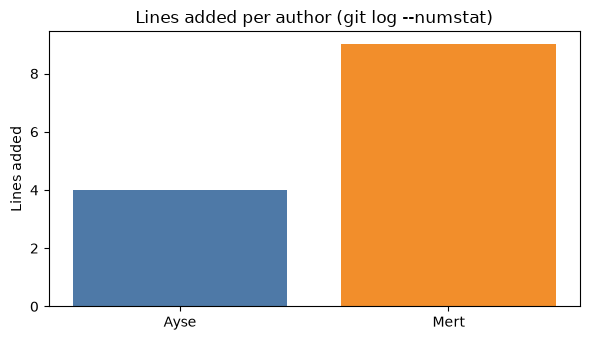

In [6]:
import matplotlib.pyplot as plt

stats = sh("git log --format=@%an --numstat", ayse, quiet=True)
added: dict[str, int] = {}
author = None
for line in stats.splitlines():
    if line.startswith("@"):
        author = line[1:]
    elif line.strip():
        a, _, _ = line.split("\t")
        added[author] = added.get(author, 0) + (int(a) if a.isdigit() else 0)
sh("git blame --date=short metrics.py | cut -c1-60", ayse)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(list(added), list(added.values()), color=["#4E79A7", "#F28E2B"])
ax.set(title="Lines added per author (git log --numstat)", ylabel="Lines added")
plt.tight_layout()
plt.show()

*Insight: Pull before you start, push small branches often, and let every change into `main` go through a pull request with CI and a review. Conflicts and broken builds become rare and small.*

## Real-World Use Case or Analogy

A remote repository is like a **shared kitchen recipe book in the restaurant office**. Each cook copies the book to their station (clone), tests a new recipe there (commits on a branch) and then proposes the change to the head chef (pull request). The head chef tastes it (review) and puts it in the official book (merge). Nobody writes directly into the official book.

Open-source projects work the same way at a global scale: thousands of contributors send pull requests to projects such as pandas or PyTorch, and CI plus maintainers decide what gets merged.